In [ ]:
import torch
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

Usando dispositivo: cuda


In [4]:
raw_train = datasets.MNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())
raw_test = datasets.MNIST(root="./data", train=False, download=True, transform=transforms.ToTensor())

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.37MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 179kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 1.68MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.7MB/s]


In [5]:
pixels = raw_train.data.float() / 255.0
mean = pixels.mean().item()
std = pixels.std().item()
print(f"Média dos pixels: {mean:.4f} | Desvio padrão: {std:.4f}")

Média dos pixels: 0.1307 | Desvio padrão: 0.3081


In [6]:
classes, counts = torch.unique(raw_train.targets, return_counts=True)
print("\nAmostras por classe (Treino):")
for c, count in zip(classes.tolist(), counts.tolist()):
    print(f"Dígito {c}: {count}")


Amostras por classe (Treino):
Dígito 0: 5923
Dígito 1: 6742
Dígito 2: 5958
Dígito 3: 6131
Dígito 4: 5842
Dígito 5: 5421
Dígito 6: 5918
Dígito 7: 6265
Dígito 8: 5851
Dígito 9: 5949


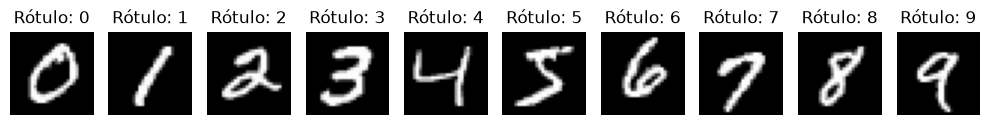

In [11]:
fig, axes = plt.subplots(1, 10, figsize=(10, 2))
for digito in range(10):
    idx = (raw_train.targets == digito).nonzero(as_tuple=True)[0][0]
    img, label = raw_train[idx]

    axes[digito].imshow(img.squeeze(), cmap="gray")
    axes[digito].set_title(f"Rótulo: {label}")
    axes[digito].axis("off")
plt.tight_layout()
plt.show()

In [13]:
from torch.utils.data import DataLoader, random_split

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# carregando dados novamente usando a normalização
full_train = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# separando 50000 para treino e 10000 para validação (seed fixa para reprodutibilidade)
generator = torch.Generator().manual_seed(42)
train_dataset, val_dataset = random_split(full_train, [50000, 10000], generator=generator)

In [14]:
batch_size = 64

# criando dataloaders para treino, validação e teste
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [15]:
import torch.nn as nn

# definindo a arquitetura da rede neural
class MLP(nn.Module):
    def __init__(self, hidden_sizes):
        super().__init__()
        layers = [nn.Flatten()] # achata 28x28 -> 784
        
        in_features = 28 * 28
        for h in hidden_sizes:
            layers.append(nn.Linear(in_features, h))
            layers.append(nn.ReLU())
            in_features = h
            
        layers.append(nn.Linear(in_features, 10)) # 10 classes (0 a 9)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

In [17]:
import time
import torch.optim as optim

def train_model(model, train_loader, val_loader, epochs=15, lr=0.01):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    
    train_losses, val_losses = [], []
    start_time = time.time()
    
    for epoch in range(epochs):
        # treinamento
        model.train()
        running_loss = 0.0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * imgs.size(0)
            
        train_loss = running_loss / len(train_loader.dataset)
        train_losses.append(train_loss)
        
        # validação
        model.eval()
        val_running_loss = 0.0
        correct = 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                val_running_loss += loss.item() * imgs.size(0)
                
                preds = outputs.argmax(dim=1)
                correct += (preds == labels).sum().item()
                
        val_loss = val_running_loss / len(val_loader.dataset)
        val_acc = correct / len(val_loader.dataset)
        val_losses.append(val_loss)
        
    total_time = time.time() - start_time
    return train_losses, val_losses, val_acc, total_time

In [ ]:
# testando 3 arquiteturas distintas de MLP
architectures = {
    "MLP-1 [128]": [128],
    "MLP-2 [256, 128]": [256, 128],
    "MLP-3 [512, 256, 128]": [512, 256, 128]
}

results = {}
trained_models = {}

for name, hidden_sizes in architectures.items():
    torch.manual_seed(42)
    model = MLP(hidden_sizes=hidden_sizes).to(device)
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    t_loss, v_loss, v_acc, elapsed_time = train_model(
        model, train_loader, val_loader, epochs=15, lr=0.01
    )
    
    results[name] = {
        "train_loss": t_loss,
        "val_loss": v_loss,
        "val_acc": v_acc,
        "params": num_params,
        "time": elapsed_time
    }
    trained_models[name] = model
    print(f"{name} | Params: {num_params:,} | Val Loss: {v_loss[-1]:.4f} | Val Acc: {v_acc*100:.2f}% | Time: {elapsed_time:.1f}s")

MLP-1 [128] | Params: 101,770 | Val Loss: 0.1367 | Val Acc: 96.13% | Time: 172.9s
MLP-2 [256, 128] | Params: 235,146 | Val Loss: 0.1197 | Val Acc: 96.28% | Time: 181.7s
MLP-3 [512, 256, 128] | Params: 567,434 | Val Loss: 0.1069 | Val Acc: 96.77% | Time: 208.6s


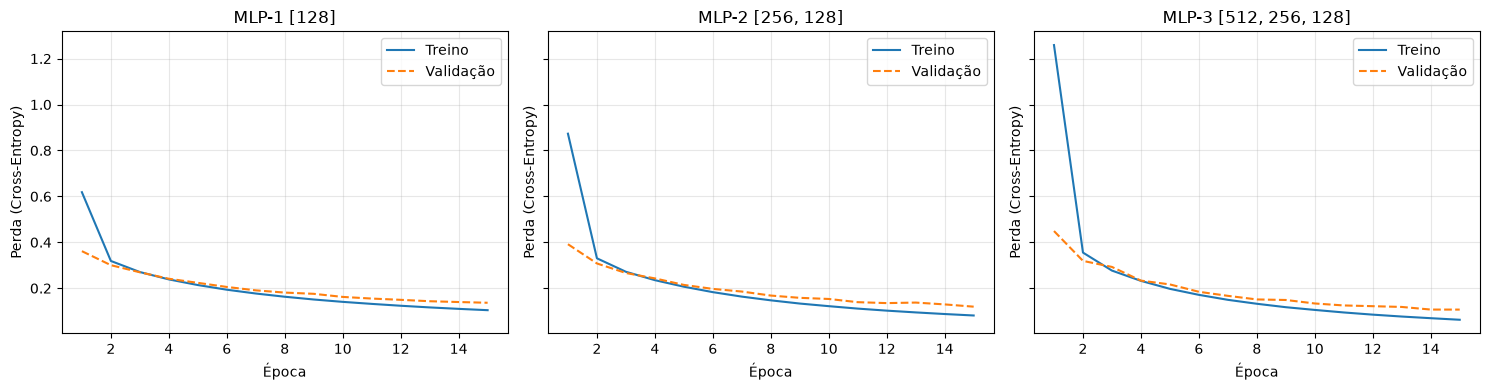

In [19]:
# Plotando as curvas de perda (treinamento vs validação) para cada modelo
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, res) in zip(axes, results.items()):
    ax.plot(range(1, 16), res["train_loss"], label="Treino")
    ax.plot(range(1, 16), res["val_loss"], label="Validação", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Época")
    ax.set_ylabel("Perda (Cross-Entropy)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("images/mlp_loss_curves.png", dpi=150)
plt.show()

Test Accuracy:  97.19%
Test Precision: 97.21% (macro)
Test Recall:    97.14% (macro)
Test F1-Score:  97.17% (macro)


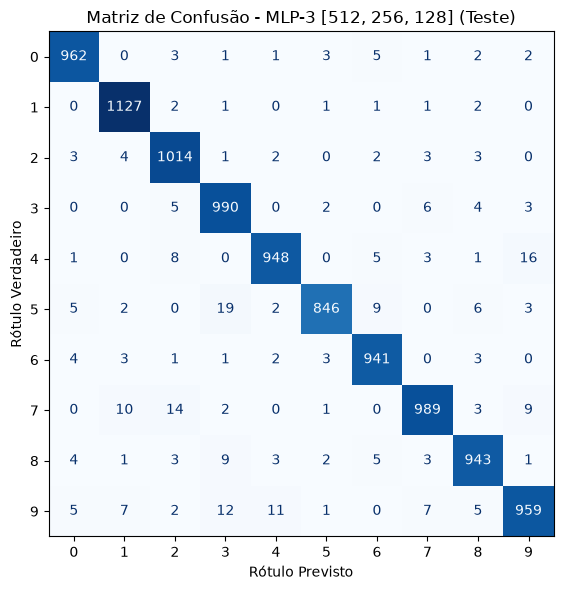


Top 5 confusões (Real -> Previsto):
Dígito 5 previsto como 3: 19 vezes
Dígito 4 previsto como 9: 16 vezes
Dígito 7 previsto como 2: 14 vezes
Dígito 9 previsto como 3: 12 vezes
Dígito 9 previsto como 4: 11 vezes


In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

best_model = trained_models["MLP-3 [512, 256, 128]"]    # teve melhor desempenho na validação
best_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = best_model(imgs)
        preds = outputs.argmax(dim=1).cpu().numpy()
        
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# métricas no conjunto de teste
acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, average="macro")
rec = recall_score(all_labels, all_preds, average="macro")
f1 = f1_score(all_labels, all_preds, average="macro")

print(f"Test Accuracy:  {acc*100:.2f}%")
print(f"Test Precision: {prec*100:.2f}% (macro)")
print(f"Test Recall:    {rec*100:.2f}% (macro)")
print(f"Test F1-Score:  {f1*100:.2f}% (macro)")

# matriz de confusão
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
disp.plot(cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Matriz de Confusão - MLP-3 [512, 256, 128] (Teste)")
ax.set_xlabel("Rótulo Previsto")
ax.set_ylabel("Rótulo Verdadeiro")

plt.tight_layout()
plt.savefig("images/mlp_confusion_matrix.png", dpi=150)
plt.show()

# listando os 5 pares de dígitos mais confundidos
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)
top_errors = np.dstack(np.unravel_index(np.argsort(cm_errors.ravel())[::-1], cm_errors.shape))[0][:5]
print("\nTop 5 confusões (Real -> Previsto):")
for true_cls, pred_cls in top_errors:
    print(f"Dígito {true_cls} previsto como {pred_cls}: {cm_errors[true_cls, pred_cls]} vezes")